# Heat flow, special shapes, and Fourier neural operators

We want to predict the temperature around a thin metal ring after heat has flowed for a fixed time. Start by observing a temperature profile, then look for shapes whose changes are easier to describe. The six sections keep the same physical problem and add opportunities to predict, compare, and fit its behavior.

All three interactive experiments are embedded in this notebook. Running them requires no companion download or GitHub connection. The calculations use NumPy, and the kernel comparison uses Matplotlib. The editable display sources remain alongside the notebook.

[Open in Colab](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/05-fno/fno-intuition.ipynb)

## 1. Watch heat flow

A thin metal ring has warm and cool regions. Its temperature varies with position $x$ around the ring. The two ends of the profile below refer to the same point on that ring. The vertical axis measures temperature relative to its mean.

Press **Play**. Heat flows from warmer regions to cooler ones, and the profile becomes smoother. Use **Reset** and the time slider to compare its initial and final shapes. Leave the component display off for now.

The whole curve changes. Could it be a sum of simpler shapes whose changes we can understand separately?

In [1]:
#@title Explore heat flow
import base64
import json
import zlib
from IPython.display import HTML, display

# Generated from the three editable HTML display sources. No runtime file or network access.
_DISPLAY_SOURCES = json.loads(zlib.decompress(base64.b64decode(
    'eNrtfQlz40ay5l+B3X6PpBqEgMLBQ0318/TYO95oH2E7YnZDVkyDJCihRRE0AOoYtf77fplVAAogeMju2X0ROzExFgFUZWXlXZVZ1U9fXkdh/uXY+PLNPL4z4vnkty8Xq6RPb/vRw3qZpFH625fGPMzD/mqDr7bleMWLRbwKl/08vo34Q+D/9uX5byvDeJPlj8uIfxrGqy14xpPR71/f9uPVzfguTLv9/u28P48W4WaZ9xdX/VmCZqb88nHd38T9RbLK5WvHfCU8V3her3cmodxu8mg+fuVPA3/gqnfhQ5yNX0396Xzmq1eLOFqimTsaRcORepesovErbz70Z6F6k1+nEd7Np6HtFa2y6C5ajV8No2A4XZwZjIbCW04CmBCCYydYP5w6lm9kj1ke3QJxMwtXGQCkMTrehg/9+3ieX49Hvr1+oBfpVbwaO2L9YNhnxvNOep2AYtPkoZ/F/4xXV+Npks6jtI83+zpZQA5v5uiB7kxB9I/Ggsfm5/sovrrOx4Ftl8jQV8M2vPVB2HmSLKchMXMeZ+tl+DheLCOCjP/279NwPab/nBnhMr5a9WMQJBvPolUepWfGFb7ytEWNEMEhQizDabTcGrFthCYWNOJw/6SmmzxPVmbbpyxaRrNckXEcr67B0bwQhfJxGs5urtJks5pvi/V0S6yBf7JRUm2brxaLBYm05O3YASWyZBnPjVLQSKbLBv0UjN1kY5+mtA7nxOUxkY+oeniS40Uy22T9uziLp8toz5SPaBiv1ptGOxAKU1vGUC+xPRFoHeahGvSTxSKL8rF7hMDBzmzx/uMmy+PFI8gIvoM32TqcRf1plN9H0aoStELGILVrlrN9gwE1TKlQGuAdh/i72tyCzbNxHk43yzCl52wfFKbLRf64jiZpuLqKLgFQqr9j2/8BqZ2RrPYb5oTNVK9UieEhjcjurjSaTJfJ7OasNkxyF6WLZXI/Vrw5BCyPHkpBdzziXqsxW8TLZdMI7mffMrqKVvOD5kIpquGwtjaow7ZemVtpzZwjLNVN9KgNG69Y7mqkEiwiSrVIRNxCbM8M0C+PZ/BzbGbGt/F8TlRU8pRKC7ofiYtrdIpWlxoWK2iB8UV8u07SHNJ1aAqrJCfZ/yzkyPIw32SAtk6yOI9hDcIp5gpYpeQQkGvpHPh3KURyIuDLMl731yHaxiuob9e3/6MQgDenlffnoGK2DLMMAYKaBmKEX68jIwuhzRCsdZQCnTQyWPJNYx5lszSeRnNj+gibsdxEmRGyUTVydEvJnSUpfbwP7yIjvF0v43yDXtabU4zWOmzhBolkIZimngkTDYF1mkCqo91gCuy1Pmm0DPMYeOSJEeeZcRuFK8ug+eX3iQF5z4xkAcTjzAAHcnyPciNZlVPRkSbt00ZjevRn12GaI96S3MAX4SPKMtJkSTFXfItJGGSg+uwa8eq7FXgaLo0QBIvukuUdTVynsyJmaOBNnMzjGSOiIjegkcc5uPfrdo8C5zensolqTwxjjpajXSGGWhXkNKbRLLkFE7PbJAGI1DK+U4QyIImPGRj/EM2JEARIASVa3MXR/V+SBwotEZEM3MCQc2cZxVuyb9uUYWJIMcW7PN1E5dQAl1TfeHDwxbXR+EHg10AI/Hykl44zsgjIo9AesjxNbojaKqD87cvTCiDpgEFR8/eubdm2yZ1s470rrOEQT8Ly6Mm3BgPTsX3Lc/A0RKhsjui/xnsPAaNrjoQlBB48yxPmMLAEmnkDy7XNoW0NAMFH3D00B4AzxINr2QNz4FjeAA++NfLNYGANXTwM8ccMPGsI0IFjDYQZCMunB88KbDOwreEIDwPLG5r+yBp6xvuBbbkDenDpwbWEzw9AZxBYjksPA6AzGFm2IAA0haFjjQDN4T5DD1jRODTV4cAKBmbgMhVGNsYmdAiDkWt5wM1nrEcBRjADzJSajfCHHoLAeO/YwrKH9ETIObZnjQb8bURPmKbP3YCE44A2EqJNT64VCBrM5acAGBBSI5eeMKEh40sjCFCbZxzQCMK3HEx5wDRzxNCyMecAFMYTmDoSpg+YNLrrWkPb9AXT0HGBE4joMBsdF3wHTGBETx6I4dOT4Cffcl1+EvQ0xF96CsBKB/0dm6Hwk2uNANOV8wMWQ8D0gS09gQ8ST8IaMwtc5ifNCDTwee6CoARDUMTEf21qCTkREB1QlSgx8CwHsgPOEszBwLJ9kjGX8ASLR64JdnoEc4h5QhiHkrpDiJ5Ncmrzt6HlD82RL/uNSBJJoBnmCNTyIey2BDMaWMI1iasOxhd47Qg8upYT0KPLWmNLeRHQEFKb8utQ6o3q6xCtS8jC8Vh15LDCGZDuKJSEsEl5FLpCuKQ9aipCEHOLaQowfFSSQLgOKZAij3A90iBFOuEOWIUkWYVnkw4pkmNNSkqk2CG8gLVIskp4I1YjyUYB8YEeKRYLiNaoZL9AD2iSEg0BaMGgEBtBKlWKlIAKeG4hbiIgfS1EUQBfUYqpgM2AOikRFmA41EmJt8Csh6Xoi6FL6qTUQsAKkTpJlRHDkaZOAnR1h4WqiRHNrFBDQfwoVdS1HVInpb4u+DoShWq7dkDqpNTetUekTsoiuDCc/qAwFq7jkzopO+I6Q1InZWJc4ZA6KevjCo/USRkmF5yGOimb5YoRq5M0Zy4s9KC0dC4sdOAWRtCFhYY6KfvowkR7pel0PeJ4YVVdGGmokzK4Lvhhl7bY9YlahZl2wX+ok7LgLgz1oDTuLvCFOim77wIaqZN0CS6guaW3cGGsWZuUJ4G5Jm0q3AzkVvdBgyFrE6gQ0COMNmkTrJhPE4ECkDZ5UvJdGG5okwPRZQRhuqFODuYwoMYw3tAnB2gTy12YbyiUAx4wjjDg0CgnIBBwXGA6VIoMD2mRBxMOnWLLQw4PNhxK5QBXj/2fTVrlAFeHnB6sONSKTBFZAA9mHHpFjwE/jkix+BFIeoIMAz+KET36pFoEyufHAekW2TjuC1s+GPK4RA0PZAgIss+08mDNfZ+RZKxgzj2C7MoZwZ67BBk6RY1h0IXNjyQuHiy6PeRHxhlSMBrIrzQjqPrQ50eipAfdG0jIjAapm+BxSRI8kiubkSQF9aAA7lBOgQaC7RGSGqSUHhEYkIeOJCxgQNfIbpOSeoABZXOIzRxNjEjbHAgZ0xmtoG7OcMDc92DeoW9k1wU/Dknh6JHsiwcD77rykcgOCy8EP5LueLDwji1B8eOIlI4dxogCF0Fa57BxoUef1I5xDuhxSHrH3McEfVh4X1FD0KNHmudA6EfUGCZekNRhYhT4wMY7JHVChj4w8lA+ElHSFB/CAO1zYPh8ggwzPyR5tpnsPuw89I+kfURfYeihgA6sOPeFpYcGkmowZFYRKM5QgkIr0kGXvDM9BqyDsCBD/jpiHXSlXPkwyqSDxVegwzqo+sL0Bhpk2BjWQTUu1It0sMAK83Y1nGH0SQeLGZGXGlTzBQlHGjUGA9bBglZkeERFyaErdVDRGTLCOqi4ANvPOqh4RIZJ4yCsP+lgwV8YKtJBxf0AvnpUyUYAB0A6qCQngAcIBqVcBXABfiV1AVk1t5TJAE6AdFBJbAAvICp5DuAGSAeVtAcQBtJBpQsBTOCw0pQAnmDglnoUwBWwDkotC5h1pQ4GYI47LDU0gDdgHZT6G3ge66DS7gD+gHRQ6X4AYRiJ0jIE5JMruxHAJQTD0qoE4JU/KG1OAKfgVRYpIG/rlvYqgK0VorRmAVjnVLYuAEjSQWUJA3QaDko7GQyGrIPKigagSuCWNjYACVkHpQUOQG+vss8B/IIYltY7gF8gHVS2PYBfsCvLH0AYSAeVXxjAL5AOKq8xsD3WQeVTBvALpIPK4wzgF1gHpT8awC+4lbcawC+wDkpfNoBfIB1Ung4rusoPYgVHm1VYotGeS209J5MB5at+sbJ0rfoij/fEHopF4yOtNT3KddhYCuPTudZgEOgteDetH65m10mKd3LviNajG9udbfdWK9EdvaPVHF1Fra9aLp9ivXyuNl+KX43NC7X9Vm4syOdq2Z+tw9U5/1fvdRM9MnkeebtBbZA1dqF4YxqAMDbBUBsQ6ukQdEJotklT2go9ZjC5P1qN9k721UbbvX+jMhbVnHnPpEC42LAoua42/TUARYvGlsu76yTJIgNzixWofHtbSduFAOxkTRtvcn8LELLNLW+LpVHE21qZkSdXEe2WvDmVTfd0niW36zClAd7JX0a4BAoMLKP9DoZ4BCAHINDBeDiiravausc0HqjGg+3GYByTuZRkyZMag97wVrrOiDntKa1BdFIS2mEHFa6j2c00ecBQv1wn9wY3WEE0Mt4Kq/YJ9SF2y0oxAm+Q0i4T7yiVe16t+4s0NG0t3ybzqDZgMcjOLcUfZTLEmJQSVHa3jG9hvWg7NEzxXemK/p323m43yzzGG8o7ZEb0sO7+thHCYWMxnd/gjz0Vec+q4dLYcMQALduNYv9249flNJnMIFv4qGHD258shEQUPK0iU4qmye05t6pv0Kndx2KDmNUdRJGbvbMENiFehTkRVd+ELLYhvwln13KTXBHsKmZluqa+0WIRz2IiHnAKK9WwjL9hsqCcRFFOYRFmeZQ2diVL47rLvOoz+eMGlRJklYW7AdedmjX9U8CZ+A3w7ucDzwxtgB/UfcEBdTAYCtkE1rzzX6QZDiuNJiWANCQpb7kTm2n3HepJmUBmNstOJS0kQNMkv+Yt5VqioPolU8u6t4hvybws2PeWmRT5VtLm/FfKSBa+541KGzZA9NkI7gREm8Ywitz1vGaapNGrV2QonLQhsiUmnlZmkFONeLyNafubwpXb8KGszgDzojU/2TasfWmg7aZa/zVeLDYZ2XCF51H+VCaXax5zGT5WyMnvaP8TXr85lY+7O6dRFuUtvX+m94e7c3VKS3d2D/yREhB5VIO0P/vDsrm5vQ3Txx3+2jK+a1rwzHBMAws7afFo/25Pqkom50p2wHzh/ToBJBY7LVs0S+O1dJvdbs+YnBtPkhKzZJXlsNhJDtWbJ7PNLRTDAnbfLCP6+ZfH7+bdzlZqsNM7k/3jhdH9grt/+sRgLKr1AcUt5Zvif8K4TiYTo0PZlU7PSCMEOivVfXcP1V61W0ZAMqL0ZzT/m/Q2tvq02KxY+fGdkprvEkjlj6wh3d5TYaPkNMN1PLlaJtNw+et1nFlXSXK1jN5aM+ry1pJqdVZ0iRddtH9rAbPvFilMhBy3gllAVd6vJF7xQ1HQAu2T5VL2Pqs6A77s+cVkUp9a76kxVdnuDOg0sVEgTKJV7+y5gK5+4I/O5d83UfoIymbEf6Y8v5EmM0m7WcFU2Xy1QdsfNrfTKO3W+LTa9EypEmzS2huV3+tApdecGBeQctc0Bpem9MD8rlNzah3T6DQcUe2VdB6dyxp8aeEAjKfW7Vil1esAaRWk176qiLtTxzMjta+1K6NIAkSWqjkMvWtAkQFJrZWWqCVAsIhZvUEZWDVgrcB0rlch3bjO8/X49PT+/t66d60kvToVtm1TxKFrTC7ZY5MtiW9D1pIJ+LpcFqRgTaMXZ4WolOoUSfHt5uEV+ud5GsPwRZnJ68ye0VAtqqfSLcgshbmIlAr88Eu3xB79w6teqQfwc0ZXgrigNqb0MpcUdf04/QgULQBI4yjrVjj0ejweKcPXxcuu1runKbHR5QUzlMzYrOYRxDKaq+704Z2sBALq9FT2k0aKm52VulQjjzJWVUTb1WiiuksaW4yTtIFwBx3jLUs/23iy75fGuKWlWqep1vgfNWPtsW7DdfeGdPiGmyrt00H00MtBe7u3A/twH9otU+Mxu6GJb/PogR1IaJwY34f5tUXrhz6MxYlE74KbXBonJ4bAO5LB3i40aBnzE2B0S3xMmbA3lVXdkrNltCBmuZBpLqbBb+5g9A3Hgy3hgj68lN2NU+DQN4YQ91m4JF0IvLM6wIyGZpPkCbvJ/6/TNHy0Fmly231aRqur/HpctH9tOM+m0f0HSKL70wrwA0CKgkY/fYdfMdBR3c+arckuV6s0LEg2s6jbhbhA90zjIw+BJwxb0h1Lkq6k+EdQ23iANbF7GmA1hw9fPcUsJzaEovN9B2LRed95/uqpS7R83WUy9ul37yQ+Vfj1rDz5liotuqL3bKKtJGyfyXjyWPv8oRzzuWd9TIBVx+js4vg8De+7W1wt1qmTmmCa5fp20iaTDUZKMZhI2iCM7YrANqUFpnjmL1SVgmX3uyUt6n6GqkCquU+vEDZimO83wCo9JLe5U0fLLpoZ10uHOj3d1kxUt7edv1/HWIEm2Qxrdmmd53EWrtcROQVeU2b5286401J31DqmvleHMVVdixquMrlMkprt7EgCdMxyum+NriToG8MfkuQEIxuSIwZ+D3+UctbMrOrZ29YERKmzG/Y0GkgMRU7ubwXli0baSJost+GsKn6A9Acq+fnqiaE/44cG+flDbwsMoqslPNG763g5h9h1C0/X4U0CwHuCZivmwGexBB5iUk8fRpppuDbaYeh2b8yPTRNRkAZLwWj5dyW5FQkkncby7yniJG7XQivhbtOqgJ081JpSw48n1YCmkTzWGqiPahQ4jxaYpX1NHl87NhwY2Y1J8vDaCUyi1WpSDdB3xVnbjHmupZ4TYVrMrPBgXmFd2bjqUAw2aFA/+y2M2Vg3ZTQ+TJjw7F3my/dPyoFPSiN6cyJOlJVW3ev2bduq6dJEorCaa0IETScZehiDLBU1ToX5OAbVhG92tJ16zEDu83cgczeYlvO2w7uqnfEH+vvV083zw4feMQOTM+2YTw/OmKhhPohxSRXz0VG17uajKH7JNMa4U9+a7zwfNRixEYPNx/Sj6/RMLvHtUNKkswuy2dEzJ52xKF/MwwwqCyEAOXzD/0M4KB8CZ9iKjFxl4GsTC9fyjxtOMnYXX53RbsZWqJVy5fY+w5gCWrdrzE7pKuu26bl6eEaMn0WVWXqZkb3esq8NE1EPwRru5zgbvKeuFIunalJlb9p/LTvTPq4KLIry0lhu71IkhQUGRapEb7RYPsqtXKpIrdIglk67fVpnkNpRUAqtYwr1KRqttM6o1M7YpR1GQzCd54ODV7bGGWEMNcRr2OWGWFBAQDSx9Qld2GoV4lxWzmpdRJtPTbe5e3DXfi2jhb7n9U7WhInwtpD4KI02HA7Wtvwk3jJiugm8AIpmR2Yt8UPlLzuXpNaa5B4ijDQNBmxDucRQEaQp1xcqgjEN3VQczRpRvdlnuigsoo0Ei9NNcLL/+Z871oS1qGkrfDB2xg/VLveE2In/XZ5VL2lhUCaB8HC2B8BP0i/vo2DZ9hgaVva2Sbxi5wGT//jWtcTYsRA8JOtwFueP+lfal/j0qdbctkZjWjM/7zGetSn1WuZ8HefbMz1mom0+Lk/DVUaB7yrfcnCwAZ01QgcKPWizKs8gJLJJx6Qs2bgjN5M7Zh5Oed08ts1OtbeOIICyTUs2pJwopHjgg2qyTqMsi6A/v+RkEbs6pXoNCmHOVjiff0NYvI8RtK6itNuZLePZTcfs9ibnT2XvGsGJB+OPZ3LZdnYU0JvocZ7cY048ZUCOF13+aeELgHa+IYJ0Pn2qvURw9SRfYFr096/yLBxGPQqzfRIBPHe5wNZ16DuS3caKj3BUuzedRn0BLamVuEvVZU7+uOi27cz0Ll9uuhRaR6mdNoMtzXPJ2G9LJEPQ7Za2pNSqLbCi5GyeJXN5BZH0EXW6tgCrpcnLBSpgfFGzkp8+Gc01a5sl/WL3inMapn9v3Q6g7dYDuwGaoHDrA/FQMdSzIYT/Yav3cXHOuyrdrI4ARXpJBktVPYxj4PtjEYQiBXIUjSAYceCUEYjQnyNDdOf5Dy5sZSTyv3irznhtdEtMKELofnyNuKNHC9vpfckjLLGGvllreRq02e8p8dVx/JMdnq2VNil4zJG0wqw/vecwGsToEywVHpDDksfapvdmcait/jl9GHsvWmEIs3Bu0nX1/hy20+stDEsht83pdU/DsMLpOP/qHI9iuTRRKAK7ko+Oy0WsfULmzyyKjh3YGexeCH2gogJ2m38QuLCd3cCpVmY+AHx9K/zkBv/jjW9talvjl8HIZD/b+45NUxyWXH8t7FI0R7YSxVoc8u/Y4l8ZW+iCszu0qHm+skSlsRXc0Ma3nc9fvwI+fy+5K5MFxZCXz2O8K+xa+VaXWENJd1Uh9tXTalO+3oYoK8eq76QD+lZaj1Wx0PzWMa0P28GZTOAWayZDiWSuJZdrxK4KaUDtolMDlSrToyetFWYqrd06Tq29VrUxMf7nLz/+gAiJ+oAzRdC2o2cxd2LNthSUatcgcHOvhXKerZmJIlJtKzqR4apKQcgGWYQnEh1uaXJJKK/TaTsk1OoHqSSvEChpV/Wxn80dvZwPbXxStTF1laCIskDur1hbI9ajsIaOdUdlPkhuzhjvVO2ebMApe0wwTqvDxVibr6nlT1F4k/EJYkKsVJoiFmUtgWzj3bPVmFSdoMfU6xCBP7xrll42fUTb4uDkRGz7DeuDlmJrKXLZkWnL8mStZ9oohK7KACgfTrLWM2bwatHy6+LLt1RcUjWsJK5ZQnCmiiAazOtQtVZnV9p5tULgPYt0vHSB4HKmLXn4wPq4bU0sQ6sn/eopbOarw8l5qMcWahsf8bZmZhSKai473ZjRrUe6u6j5pOh+ps31rKh5qiwa1yXQrM4nVSVNryzYaOaoSamUUaImSs3e0aUUeLWOUoTkt8RHa5Xca5nRHRwKN5mWQCy5k2OmXQCoLagUSmVoV2JrVmi9pl79CqfeSdnqdGjbtay08ql6HVQrKdoJ+azv+XIVfSWUaQRRyvKGJNOkWtb7L+tYunXlibbFhOsvKzEpkefrrgpV19wYPilKHAF8dk11mh2zJEXRQ9MdLn+E6hyU4DpqdoVHjc4tIzBzXj5CydMDIylDuGf2TfCl25TmaD902jzYA5s66zWNVAaKhfjPbG5/nGYRYrCU9bxTlhF1esYqum+06TIkK5GPXBNXwNVE/7mnfrw5LUszi3LNL03jy2UUpis4sO271oovFMTvvEBNb9S4COZll6f5ruuNen/2yrKWm7pqGB55Y1mtz7Xbck/ZnjvSap0P3oO0t+dLLj2q7Y7tBmstlnwpFRZumYbZVUp3CtF/+3RIaIkQjXizuV1l4zRaR2HedU1YZbn0dxYpsYruRBIvon/zojRFkJ3tqyuvlkmYj7mC6Oyl91/VIMry9fqVVw1m1m7AejWfBqGwD1BULoAzs/3rC66Yarl97pCIqQrz5iVwxe1rg/L2tc9xD1zzarnmtXCvwnAqprPW++AOzKBxp9sO1h1xo1t5deKhu9y2GPX/4EauLRxqV2qV10fuu0qrBgJqwGTR5bs6ErMM1xnvH/KPLRn7M4qVX7ewLCep1yTxTJ0dZQIpbS6NMITgVhel+Wi+iPy9Q44XcZpBSGnTu3V4vQFQ0UankpU9sF9wN9p/3UbzOOxWTsm3ocAUWB40v+0GF+ZVWgNS+5bby67d83fhyoB+goH57JqXmfLkyNbNZW/fnKL51pEOJWh0OJMDEy0RoJ2Sk4f41lj5xlzBrY69ZQhkeb2Qbvh1uKA6jOiOiv5lnLPr/jCa/dZRvmD/Ub5fIaNRzoteHZNV+3nWTJ7xajttXFrivaeLpRnYdaDsVRiEi+l061ixJM3Bw8UHgA+E74ROBVyFesV0P8sY0p9VY/zvZJMWhMWS5PCJZU2Cm0eWf/5tI+yhYzTPnKFL6hQnzs4dy9YPl9VP0XLTw+fGHEvsPjbmNEXo++oY6s+SvC3HeSXybivy7vHIu/9K5N39yA9akR8cj/zgX4n8oIH8bvliH4i/UZom6RGHzhrdVTRGbRrH79gEwBy3HL97T+8NKg3lS6TL03ctIPYeANTtZwVkjyrRFmScHTjNXdnrrw2lfXT4eh7dsh3m3QR1wWMaxuRu4Hbh+ngzc5XEtILN5FlouvZQzrPcnaQ4J0wNOnhnJGxRk9TYZGR48KNCsX5OW4YaNXYzEckj0NF2mKxHDoh0ktQOVVPV+vmbPMX/r89pq/fNKX7Qw7dxzmae0OSJlF92HCL/tSdbnBK0Uwm5GmiazB91WjLqfXrLgsTfy3PA/HE/E+hUH/nB0FiqGSsSfgtrGvON0LQdZnzNxFtGEOdvf/jRCJdZYlyHmbGIpNMib7mKlpIxXC5xD1aBYSsJD74l2nEwuH7QcnK+dcxysveQpR6VaGcs5RHLT592HZekJJc8XnnU6crJv89Wfu6zldlmTZo0n5yekEz94/3Xf/nHux9/+Pa7/2GcnBYn7PSyu9UivpoUvT590oWldlZycuGYrjm4NFebieV4Ju+p0TVQ1XY3NbF8k46SNTaOcw7SJtq1t+oc10eMFp7U8hHFUaIyB9FMNrFfyiYtxfqBp2r1J+fVCTWuDpmcl1X23fi1w6Uf+C9d+NN7bamy+1mS4eNNb2tEKTXZRI5c7ekz+N8Z/O+HJtFrnumSSUuQk0mpkdGU1DLlaKYa/LncAu7Wz2P+Pskm562naE0Opie/dztWEVk3T5fyTi8Yp9qkTqdnFr9d7feg06ufb5V3HGsdi0Rn1X3rzaB4c6lpvLzNn2WHDheaCzbtE01SW0+C0iFMUIqOgD5JjKLJzkOf+46pmnwMFI6sOP15Y95dth/6zHq9qF6Ghba9Myg54QEVrw52RrXsOh/pVGyPzprJKD41EMqqCjILu078ebZTirea88NEPzHi2bb5OAmrU3vmHctm9vquOmQiNd4qBfShZ9q9M+2M3tvO+8648z0fZ6kXVPMIW0daHOH3g8HWWbzaGbz203dPLQfnJrU6OZbZQ6fmqtXJRE1ul51RskY13JWG8xA7iuvqZw2wFP3Q7Hioru6JTkDM6b7/0vnr98zkiVqjY4WWFMs5DrT4bnMu1GgOufu8jSy2u9cr7YSstBNVpZ26D7pWaHlxsUU5s6MWsx2T68kvzaKNMk8dtR7Fd/pYcQFf5CqSv2gl/RehKXcRqVb9Ehxpn0/9OE2hGDsr3baq3Kxh23ke+vncq586gLPSjxxIbWlHqqzHqqvEHdVl+a758hMGew8YVFgqka2QvGckn5Tlpqo1ubpShRr3vTNpmqsv91ruWa9uKm5XuJUR/aTioGZBQmVBumG/xn5CE84NtsPEmiS5pYofwKi10cEwkPAkNO0mAryKk2qf/Z7m3RKhUw2wVl8jnQn3ahQxffi5uNde7kRxGyou4h+gwjcPspQJ4Wf9wHAtQC08UqOORr2GrdQbF1fpf8OzUEzg8cioHqiRUEysmCtfSJIfyPBynFYZtPbcblnSVqZRJfU4vN+XQq1FgaenBhZc1aKwNFSMSr/YU6iuuTrjZtoKT5aOYUWEBZJcOV5HaWRVBejs83XXpIduW9F4JbOqiwrMdLGNpcSRi1ONVCB1EZOOmbViAAm2RZC3AVdgwy0wyou2SnDbmaEy9rEsS9KgGTjTyrMI4KpVKTwq/dlyPvppJIK2ZTWaM06T+x1REyxeWjtmeqFkuxE/9MzKvAQ9swqCVTvEws2IAyFxYSZqJUZBr7LFpNZllDOLlsvdaM6BJrVoibgo1a7O4qBBo7STKag+o2Xroa4idC63OKrT7Aus1qOzxlUzLMYNuyHflrrYKOQoYuNDVRO6uhex8pkeK+9BlRaOW9WtFLW21RYgjNUrC/5VhQXaHsbjdnGB/nVvgUGz4X/PIoMtLI8sNNjq99Jigy0ALyo4aO39eYoOtkBbK7VCPbbswFmkRpkJk4Q4PMB2ZcML//W34KUEL0oaaISxc0b75UpshH0Y6X3lCPax5QhbUD9L2cQW1B2FBv83/rW5fWUF24UOR8yirdignTmfs+CgVWZVwr+Z4W8UABwE88IikyMg/rlqiO2yhx31Ebuy6EEti77fnuzJo+9JoIf6/bQy6qB3cZZR/mTB1Zqr2eOOFPqqzAZ8x3Ji8G0aliHz1WOjy889mZ6g63JT2ictUuT874Wtlo+GypnuunuxnKWWtNYS6vjMS6H6Pzhl702o/9TI56sq+DmYmstaguz3DeWN1B25tYz69vh0SOUlw2/n82nDqH45MaTnaiW3Ker5/J1EKjP7bSnx1cvS7hLD4v7Ul8Nrpth/ambX9/D6hZl1dNGTu7tyu2gmQ8td+d2+w/+mWJHird/JujfD+3d5+QZfVEdDMiMTJTW1THUjkQqcpJy1ZFK/Xq+hGlVCTDY8cLfqavmCq1l3s4DtMSH3x648fXEmrmnZOrzh/NI83HEZuIMJBbYIvB4tLEunZ5KGF+/oN17JXYjipZStcjX57zzfn8rzVUmTiWNKyZ+r1ej/H/mSo5IHvm0ec+Xe2VF3DjXSAL79ARQ46vog2v5vrVAr7nNjMNmx1/vQJr8Yapv84gWb/PWEk9yi3ZdvcoMD+SY3oHyTBPS2TDA90L7wWAnmW7VteqJ95u/br3floMSw3HC3e3LU1hyU5x+VgzruEi/WwdZ7VqqsR+NOi8O3JNWHYJXdMUaZP9lKbRx7F9PTgxQRPq0v3OHOk+MFozpVGILgtAgo9CAVvfQ2tSadrZx5toaepZvbSTHAhWK5/AO8bLPx5nJ8YcsdxHCaKcHp0U1CrcUEF5ZvUgrn0pze1xX/JZdr7Ltao7hZ477Q+aNu0iCVL1N9ZZxKxz3lndP/jNLElP+kBJmE/D7RibfnPg1Wfnmdxj2fxYfmj6Tmjw6k92zTMcVl/cKMlu1gudUxEfbrLoZwbS6T4Asy9I3gizIDpOUA+8K7NC8KpstvhRQPa0nAuyIJ+HBZx+G4Kyhezx/oFoKRDxLYJ3fqMgInKG8i4LfVpRN/5A4JjPF6WLtHYsj//JcccvdVEnea+entPI5/DAaktOD1i+6SeD4gReUQ6g4P4Yndt/Z9v2PBpcuqnmsq84/qRlYV+tVOv0/kx7bT76q5tBXNuwkKC/WzdBCUM68W5rRKBubtS4LO1gAtJ3urAbicvQFCrfwzpb02Ky0W7L/ApRcmcGI4VSafS+Vl/hN4vStW80XbcJlT4p/XQY5lVKttfiMQ+dKNvfSv4YQzug2QzIXV2XF4X0V/xd0Y8rGRoSS4omxSKKi4bDRTIWWDjUemMI9KUx5IUWoJEV0SDlzooSjwhfqxC9xL8isT56weVv93Sp08/x8QoQus')))

def show_experiment(name, configuration=None):
    source = _DISPLAY_SOURCES[name]
    if configuration is not None:
        source = source.replace('/* FNO_LAB_CONFIG */ null', json.dumps(configuration))
    display(HTML(source))

show_experiment('heat')

## 2. Discover special oscillations

Choose **Compare all three sine waves** in the display, press **Reset**, and predict which wave will shrink fastest. All three start at amplitude one. Play or move the same time slider to compare them at the same instant.

- What stayed at the same positions?
- What changed?
- Why might rapid spatial variations disappear faster?

<details>
<summary>After observing the waves, reveal the mathematical explanation.</summary>

The waves oscillate in **space**, not in time. Their peaks do not travel under diffusion. Their amplitudes shrink. A sine's second derivative is

$$\frac{d^2}{dx^2}\sin(kx)=-k^2\sin(kx).$$

The second derivative preserves this spatial shape and multiplies it by $-k^2$. Such a shape is an **eigenfunction** of that operator. The heat equation relates temperature change to this derivative, so a larger $k$ gives a faster decay. The difference between the three waves comes from the factor $k^2$.

</details>

## 3. Build the field from waves

Choose **Three waves together**, press **Reset**, and turn on **Show components and amplitudes**. The green temperature profile contains a broad variation and smaller, more rapid variations. The colored curves separate those contributions.

### What does it mean to add waves?

Keep the three shapes $\sin x$, $\sin3x$, and $\sin7x$ fixed. Multiply them by $1$, $1/2$, and $1/4$, respectively. Then add their values at each position,

$$u(x,0)=1\sin x+\tfrac12\sin3x+\tfrac14\sin7x.$$

For example, at $x=\pi/2$ the three sine values are $1,-1,-1$. The temperature relative to its mean is therefore

$$u(\pi/2,0)=1-\tfrac12-\tfrac14=\tfrac14.$$

The component amplitudes are not temperatures at particular positions. They describe how much of each entire wave contributes to the field. At one position the components reinforce each other; at another they partly cancel. Adding them at every position reconstructs the complete curve.

Click a colored component curve. Its corresponding amplitude bar is highlighted. Click another bar to identify its curve. These are two descriptions of the **same temperature field**. The curve specifies values by position. The three numbers $(1,1/2,1/4)$ specify that curve by its contributions from the three chosen shapes.

### What changes as heat flows?

Section 2 showed that an individual sine keeps its wavelength and peak positions under diffusion. Only its amplitude changes. Call the changing amplitudes $q_1(t)$, $q_3(t)$, and $q_7(t)$. The evolving field can therefore be written as

$$u(x,t)=q_1(t)\sin x+q_3(t)\sin3x+q_7(t)\sin7x.$$

The shapes depend on position $x$; the amplitudes depend on time $t$. Heat flow is linear, so evolving the initial sum gives the same answer as evolving each component separately and then adding the results. Thus these three changing numbers determine the entire changing profile.

Before moving time, predict which bar will shrink most. The faint outlines mark the initial amplitudes. At the final time, mode 7 contributes very little. Its disappearance removes the finest variations from the sum, leaving a smoother profile.

### What does the FFT compute?

So far, the amplitudes were supplied when the profile was constructed. In an actual input we may receive only sampled temperatures $u(x_j)$. Fourier decomposition recovers the wave coefficients from those samples. For this example it recovers $1$, $1/2$, and $1/4$.

The recovery works because different sine modes are orthogonal. Multiplying the field by a matching sine and averaging isolates that component; contributions from the other sine modes cancel. The FFT efficiently computes Fourier coordinates for all resolved modes. It changes the representation of the field, without evolving it in time.

General periodic fields also need cosine components, or equivalently complex Fourier modes. Our three-wave example uses only sines so that the bars have a direct interpretation.

<details>
<summary>Why does the next cell use −2 times the imaginary part of the FFT?</summary>

With the normalization used here, the complex coefficient is $\widehat u_k=N^{-1}\sum_j u(x_j)e^{-ikx_j}$. Its imaginary part is minus the average of $u(x_j)\sin(kx_j)$. The real sine amplitude is

$$q_k=-2\operatorname{Im}\widehat u_k
=\frac{2}{N}\sum_j u(x_j)\sin(kx_j).$$

For a unit sine, the average of its square on this grid is $1/2$, so the factor two returns amplitude one. In this resolved sine-only example, other modes average to zero. The next cell checks that the recovered amplitudes match the three bars at time zero.

</details>

In [2]:
import numpy as np
from IPython.display import Markdown

N, NU, T = 128, 0.14, 0.65
MODES = np.array([1, 3, 7])
AMPLITUDES = np.array([1.0, 0.5, 0.25])
x = np.linspace(0, 2*np.pi, N, endpoint=False)
basis = np.sin(MODES[:, None]*x)
initial = AMPLITUDES @ basis

def rfft(u):
    return np.fft.rfft(u, axis=-1, norm='forward')

recovered = -2*rfft(initial)[MODES].imag
assert np.allclose(recovered, AMPLITUDES)
display(Markdown('| Sine mode | Amplitude from FFT |\n|---|---|\n' +
                 '\n'.join(f'| {k} | {a:.2f} |' for k,a in zip(MODES,recovered))))

| Sine mode | Amplitude from FFT |
|---|---|
| 1 | 1.00 |
| 3 | 0.50 |
| 7 | 0.25 |

## 4. Solve by multiplying the coefficients

The previous display reduced an evolving curve to evolving amplitudes. Now determine how each amplitude changes. Heat flow on the ring satisfies

$$u_t=\nu u_{xx}.$$

The left side measures temperature change in time. The right side measures spatial curvature, scaled by the diffusivity $\nu$. Near a warm peak the curvature is negative, so temperature decreases there. Near a cool trough the curvature is positive, so temperature increases.

### Follow one component

Start with a single shape and an unknown amplitude,

$$u(x,t)=q_k(t)\sin(kx).$$

A time derivative changes the amplitude, while a second spatial derivative acts on the sine shape,

$$u_t=\frac{dq_k}{dt}\sin(kx),\qquad
u_{xx}=-k^2q_k(t)\sin(kx).$$

Substitute both expressions into the heat equation. Both sides contain the same spatial function, so their coefficients must agree,

$$\frac{dq_k}{dt}\sin(kx)=-\nu k^2q_k(t)\sin(kx)
\quad\Longrightarrow\quad
\frac{dq_k}{dt}=-\nu k^2q_k.$$

The amplitude decreases at a rate proportional to its current size. A fixed fraction remains after a fixed time interval, giving exponential decay,

$$\boxed{q_k(T)=\underbrace{e^{-\nu k^2T}}_{\text{multiplier for mode }k}\,q_k(0).}$$

This explains the earlier observation. Increasing $k$ increases the decay rate by $k^2$. Mode 7 has 49 times the fractional decay rate of mode 1. Its peaks do not move; its amplitude decreases faster.

### Distinguish the amplitude from its multiplier

Here $\nu=0.14$ and $T=0.65$. Apply each multiplier to that component's initial amplitude.

| Mode | Initial amplitude $q_k(0)$ | Multiplier $e^{-\nu k^2T}$ | Final amplitude $q_k(T)$ |
|---|---|---|---|
| 1 | 1.00 | 0.913 | 0.913 |
| 3 | 0.50 | 0.441 | 0.220 |
| 7 | 0.25 | 0.0116 | 0.00289 |

For mode 3, $0.5\times0.441\approx0.220$. The multiplier tells how much of the component remains. The bar height is its resulting amplitude. In the equal-amplitude comparison of Section 2, every initial amplitude was one, so the bar value and multiplier happened to be equal.

Choose **Three waves together** and **Show final state**. The reconstruction is approximately

$$u(x,T)=0.913\sin x+0.220\sin3x+0.00289\sin7x.$$

This is the same field shown in green. At the position $x=\pi/2$ used in Section 3, the temperature is now approximately $0.913-0.220-0.00289=0.690$, compared with its initial value of $0.25$. The negative contributions from modes 3 and 7 have moved toward zero. Their changes exceed the decrease of mode 1, so this position warms while other positions cool.

A spectral solution obtains the entire final field by finding the initial coefficients, multiplying them by their decay factors, and adding the resulting waves.

### Read the operator as a change of coordinates

Call the heat-evolution operator $\mathcal L_T$. It maps an entire initial field to its field at time $T$. Its Fourier representation is

$$\boxed{\mathcal L_T=
\underbrace{F^{-1}}_{\text{reconstruct}}
\underbrace{\Lambda_T}_{\text{multiply each mode}}
\underbrace{F}_{\text{decompose}},\qquad
(\Lambda_T)_{kk}=e^{-\nu k^2T}.}$$

Read this expression from right to left. $F$ obtains the input coefficients. The diagonal matrix $\Lambda_T$ scales each coefficient without mixing it with another mode. $F^{-1}$ reconstructs the final field. These coordinates simplify the operator because its eigenfunctions evolve independently.

The same multipliers work for every initial field on this periodic domain with the same $\nu$ and $T$. Changing the initial amplitudes changes the answer, but does not change the decay factors. This is a rule for transforming a family of fields. Could examples reveal that rule if the PDE were not supplied to the fitting procedure?

### How does one input location affect another?

The Fourier description follows whole waves. The same heat operator also has a description in terms of localized inputs. Place a unit amount of initial heat at position $y$ on the ring. At a positive time $T$, its influence has spread to other positions. Denote the resulting profile by $G_T(x,y)$, where $y$ is the input location and $x$ is the location where we measure the response.

This response is the heat equation's **Green's function**, also called its heat kernel. It answers how much a localized input at $y$ contributes at $x$ after time $T$. Its integral over output positions is one, because heat flow on the ring preserves the total heat.

An arbitrary initial field can be assembled from many small localized inputs. At grid point $y_j$, a small interval of width $\Delta x$ contains an amount proportional to $u_0(y_j)\Delta x$. By linearity, its contribution at $x$ is $G_T(x,y_j)u_0(y_j)\Delta x$. Adding all contributions and taking the continuum limit gives

$$u(x,T)=\int_0^{2\pi}G_T(x,y)u_0(y)\,dy.$$

This is an integral kernel operator. More generally,

$$ (\mathcal Kv)(x)=\int_\Omega\kappa(x,y)v(y)\,dy.$$

The kernel specifies the influence of each input location on each output location. It may come from known physics, as $G_T$ does here, or be part of a learned model. The integral combines those influences with the actual input field.

### When is a kernel a convolution?

For constant diffusivity on a periodic ring, shifting the input shifts its heat response by the same amount. Only the separation between the two positions matters,

$$G_T(x,y)=g_T(x-y),\qquad
u(x,T)=\int_0^{2\pi}g_T(x-y)u_0(y)\,dy.$$

Here the separation is periodic. This integral is circular convolution. Translation invariance is the condition that reduces a general two-location kernel to a function of separation. Fixed boundaries and variable coefficients generally change that condition.

### Why do its Fourier weights describe the same operator?

Apply a convolution kernel to one wave $v(y)=e^{iky}$. Changing variables to the separation $s=x-y$ gives

$$\begin{aligned}
(\mathcal K e^{ik\cdot})(x)
&=\int_0^{2\pi}g(x-y)e^{iky}\,dy\\
&=e^{ikx}\underbrace{\int_0^{2\pi}g(s)e^{-iks}\,ds}_{R(k)}.
\end{aligned}$$

Periodicity permits the shifted integration interval to be written again as $[0,2\pi)$. The output is the same Fourier wave multiplied by one number. Thus $R(k)$ is both the convolution's frequency response and its eigenvalue on that wave.

The descriptions are equivalent,

$$\boxed{\int_0^{2\pi}g(x-y)v(y)\,dy
\quad\longleftrightarrow\quad R(k)\widehat v_k.}$$

The kernel describes influence between positions. The multipliers describe the action on waves. For heat flow, they are exactly the factors already derived, $R(k)=e^{-\nu k^2T}$. The next figure shows the heat kernel's point response and those same modal factors.

<details>
<summary>Kernel normalization with the Fourier convention used here</summary>

Field coefficients use $\widehat v_k=(2\pi)^{-1}\int_0^{2\pi}v(x)e^{-ikx}\,dx$. The multiplier above includes the unnormalized integral of the kernel, so

$$g(s)=\frac{1}{2\pi}\sum_{k\in\mathbb Z}R(k)e^{iks},\qquad
\widehat{\mathcal Kv}_k=R(k)\widehat v_k.$$

In the discrete calculation, `irfft(R)` with its default inverse normalization gives convolution weights whose sum is one. Dividing those weights by $\Delta x$ gives samples of the physical heat-kernel density. These normalization factors keep the point-influence and multiplier calculations consistent.

</details>


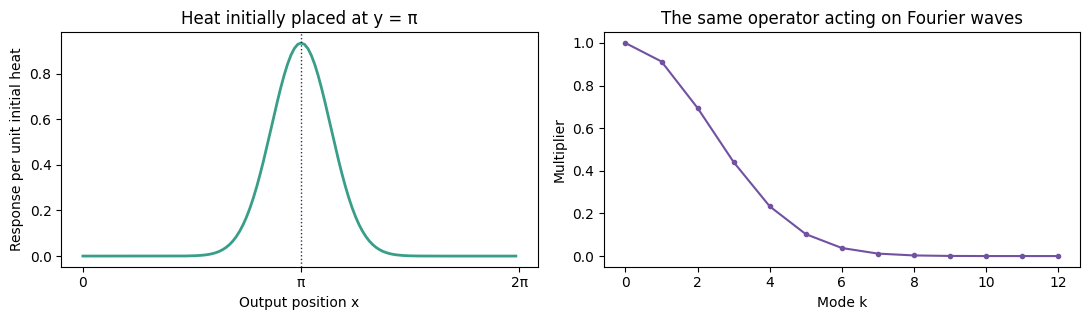

In [3]:
import matplotlib.pyplot as plt

kernel_k = np.arange(N//2+1)
heat_response = np.exp(-NU*T*kernel_k**2)
dx = 2*np.pi/N
kernel_weights = np.fft.irfft(heat_response, n=N)
kernel_density = kernel_weights/dx
source_index = N//2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(x, np.roll(kernel_density, source_index), color='#399e89', lw=2)
axes[0].axvline(x[source_index], color='#253349', ls=':', lw=1)
axes[0].set(xlabel='Output position x', ylabel='Response per unit initial heat',
            title='Heat initially placed at y = π', xticks=[0, np.pi, 2*np.pi],
            xticklabels=['0', 'π', '2π'])
axes[1].plot(kernel_k[:13], heat_response[:13], 'o-', color='#7251a1', ms=3)
axes[1].set(xlabel='Mode k', ylabel='Multiplier',
            title='The same operator acting on Fourier waves')
fig.tight_layout()
plt.show()

direct_convolution = sum(kernel_weights[j]*np.roll(initial, j) for j in range(N))
spectral_solution = np.fft.irfft(heat_response*np.fft.rfft(initial), n=N)
assert np.isclose(kernel_weights.sum(), 1)
assert np.allclose(direct_convolution, spectral_solution, atol=1e-13)

## 5. Learn the multipliers

Keep the three wave shapes fixed and suppose their decay factors are unknown. The next display gives an initial field and an observed final field. Your task is to determine three numbers $R_1,R_3,R_7$ that transform one into the other.

### What does a slider change?

For the initial field used throughout the lesson, the prediction is

$$u_{\rm pred}(x)=R_1\sin x+\tfrac12R_3\sin3x+\tfrac14R_7\sin7x.$$

Each slider changes a multiplier, not an output amplitude directly. For example, setting $R_3=0.4$ makes the output amplitude of mode 3 equal to $0.5\times0.4=0.2$. Its wavelength remains unchanged. The display adds the three adjusted waves after every slider movement, so you can see the predicted field immediately.

Start with $R_1=R_3=R_7=1$. This returns the initial field unchanged. The observed field is smoother, so some components must shrink. First adjust the broad component with $R_1$. Then adjust the smaller variations with $R_3$ and $R_7$.

Can a change in $R_7$ repair an error in the broad shape? Can a change in $R_1$ remove the finest wiggles? Each slider controls a different spatial shape, which is why separate coordinates make the fitting problem easier to understand.

The reported error compares your predicted field with the observed field over the whole ring. Matching one temperature value is insufficient. The sum of your adjusted waves must match the target at all positions.

### What will “Learn from data” do?

After trying the sliders, press **Learn from data**. The button determines the same three numbers automatically. It uses 64 observed initial-final field pairs, each with a different combination of the three sine shapes. The same $R_k$ must explain mode $k$ in every pair.

The data generator uses the heat equation to create the observations. The fitting calculation receives their input and output coefficients. It does not receive the analytical decay factors. Those factors are revealed afterward for comparison.

This is a controlled demonstration with noiseless data and a linear operator on the represented modes. It makes the learned quantities directly inspectable before introducing a larger nonlinear network.

In [4]:
rng = np.random.default_rng(17)
training_amplitudes = rng.normal(size=(64, 3))
train_inputs = training_amplitudes @ basis
decay = np.exp(-NU*T*MODES**2)
train_targets = (training_amplitudes*decay) @ basis

# Extract coordinates from observed fields, then pass only these pairs to the fitting controls.
observed_inputs = -2*rfft(train_inputs)[:, MODES].imag
observed_outputs = -2*rfft(train_targets)[:, MODES].imag
fitted = np.sum(observed_inputs*observed_outputs, axis=0) / np.sum(observed_inputs**2, axis=0)
assert np.allclose(fitted, decay, atol=1e-13)
assert np.allclose((AMPLITUDES*fitted) @ basis, (AMPLITUDES*decay) @ basis)

show_experiment('learning', {
    'modes': MODES.tolist(), 'nu': NU, 'time': T,
    'amplitudes': AMPLITUDES.tolist(), 'target': (AMPLITUDES*decay).tolist(),
    'inputs': observed_inputs.tolist(), 'outputs': observed_outputs.tolist(),
})

Mode,Fitted from pairs,exp(−νk²T)


### How does the automatic fit find each number?

Take mode 3 in one training pair. Let $a_3$ be its amplitude in the initial field and $b_3$ its amplitude in the observed final field. The model says

$$b_3\approx R_3a_3.$$

If $a_3=0.5$ and the observed $b_3$ is approximately $0.2204$, their ratio suggests $R_3\approx0.4408$. Another input might contain amplitude $1.5$ and produce approximately $0.6613$. It suggests the same ratio. The multiplier is a property of the operator at this fixed $\nu$ and $T$, while the initial amplitude changes from example to example.

The code first applies the FFT to the observed fields to read these coordinates. It then fits one input-output scale per mode. For the real sine amplitudes used here, least squares gives

$$R_k=\frac{\sum_{j=1}^{64}a_k^{(j)}b_k^{(j)}}
{\sum_{j=1}^{64}\left(a_k^{(j)}\right)^2}.$$

This chooses the scale that minimizes the total squared mismatch $\sum_j(R_ka_k^{(j)}-b_k^{(j)})^2$. It combines information from all pairs rather than dividing by a single possibly small amplitude. If a mode were absent from every training input, the denominator would be zero and the data would not identify its multiplier.

The three fitted numbers can now transform a new combination of these modes. Apply the FFT to its initial field, multiply each retained coordinate by its fitted $R_k$, and reconstruct. The fit has learned a transformation shared across the input family, rather than storing one final temperature curve.

### Which parts are learned?

The sine shapes and coordinate transforms stay fixed. The unknowns in this experiment are only the three multipliers. A direct fit suffices because the model is linear in those unknowns. A full FNO has many interacting parameters and is usually trained by gradient-based optimization.

The spectral calculation and the learned layer use the same sequence of operations,

$$\begin{aligned}
\text{Spectral method}\quad &F^{-1}\Lambda_TF
&&\text{multipliers derived from the PDE},\\
\text{Learned Fourier layer}\quad &F^{-1}R_\theta F
&&\text{multipliers fitted to observations}.
\end{aligned}$$

For this example, both should recover the same factors $0.913$, $0.441$, and $0.0116$. The nearly exact agreement is expected because the data are noiseless and the true map has exactly the form being fitted.

The learned computation is **FFT, learned multiplication, inverse FFT**. The FFT describes the input with wave coordinates. The learned weights transform those coordinates. The inverse FFT returns temperature values around the ring. This is a learned **linear Fourier layer** on the represented modes. The next section explains which capability must be added for nonlinear physics.

### What spatial kernel has the layer learned?

Learning frequency multipliers also specifies a convolution kernel once the response at every frequency has been chosen. A truncated Fourier layer sets unretained multipliers to zero. With the normalization above, its spatial kernel is

$$g_\theta(s)=\frac{1}{2\pi}\sum_{k\in\mathcal M}R_\theta(k)e^{iks}.$$

The retained set $\mathcal M$ includes matching positive and negative frequencies for real-valued fields. Each Fourier wave extends around the whole ring, so this finite sum generally gives a kernel with global support. Learning only a few modal weights does not restrict the operation to a few neighboring grid points.

Our fit identifies the action on modes 1, 3, and 7. If the other multipliers are set to zero, the resulting global kernel reproduces heat flow on the represented three-wave family. It need not equal the full physical heat kernel on arbitrary inputs. For example, heat preserves a constant input, while setting the unretained mode-zero multiplier to zero removes that constant. Many spatial kernels agree on the action of only those three modes. The data identify that restricted action; the architectural choice specifies what happens at the unretained modes.

This is the kernel connection in [the original FNO paper, Section 4](https://arxiv.org/html/2010.08895v3). The Fourier branch learns a global convolution through its response to waves. The full nonlinear network then composes such operations with channel transformations and activations.


## 6. Nonlinear physics and FNO

Every multiplier so far changes a mode already present in the input. To see the limitation, use the input $u(x)=\sin x$ and try to predict the target $u(x)^2$ in the next display.

### First try a linear multiplier

Change only $R_1$. The prediction remains $R_1\sin x$. You can enlarge the wave, reduce it, or reverse its sign, but it still has one oscillation around the ring. The target has a different shape. It is nonnegative and has two peaks.

Watch the predicted amplitude at mode 2. The input has zero amplitude there. An independent multiplier would produce $R_2\times0=0$, whatever value $R_2$ had. Changing the weight on mode 1 cannot supply the missing mode 2 either. This limitation applies to the entire linear Fourier layer, not just to the slider range.

### Then change the operation

Select **Apply pointwise square**. “Pointwise” means squaring the value separately at every spatial position. It does not mean squaring the Fourier coefficients. The display now reconstructs the wave, squares its spatial values, and examines the modes of that new field.

What appears at modes 0 and 2? Set $R_1$ to one to match the target, then return to **multiplier only**. Observe which frequencies disappear again.

In [5]:
show_experiment('nonlinearity')

### Why did the square introduce new modes?

The identity

$$\sin^2x=\tfrac12-\tfrac12\cos2x$$

expresses the squared curve using a constant and a wave with two spatial oscillations. Mode 0 supplies its positive mean. Mode 2 supplies its two peaks. The display shows amplitude magnitudes; the minus sign sets the phase of the cosine component.

For an input $a\sin x$, the square is $a^2/2-(a^2/2)\cos2x$. Thus the newly created amplitudes depend on the input amplitude. Nonlinearity changes both which modes are present and how their amplitudes depend on the input. This is what independent, fixed linear multipliers cannot represent.

### How does a pseudospectral solver handle this?

Burgers' equation combines nonlinear transport and diffusion,

$$u_t=-u\,u_x+\nu u_{xx}.$$

If the Fourier coefficients of $u$ are known, its derivatives are easy to obtain. Multiply mode $k$ by $ik$ for $u_x$, or by $-k^2$ for $u_{xx}$. The product $u\,u_x$ requires another operation, because it couples modes.

A pseudospectral evaluation proceeds as follows.

1. Keep the Fourier coefficients of the current physical field. Use the known derivative multiplier $ik$ to obtain the coefficients of $u_x$.
2. Apply inverse FFTs to reconstruct $u$ and $u_x$ at the grid points.
3. Multiply those grid values to form $u(x_j)u_x(x_j)$. This physical-space product produces the mode interactions.
4. FFT the product back to Fourier coordinates. Combine its negative with the viscous term, whose multiplier is $-\nu k^2$, to obtain the time derivative of the coefficients.
5. Use a time integrator to advance the physical solution, then repeat.

The derivatives are spectral operations, while the nonlinear product is evaluated on the grid. That combination is the pseudospectral computation. The FFT of the product contains the newly generated frequencies. It computes the mode coupling through a product of spatial values rather than an explicit sum over pairs of Fourier coefficients.

Every transformation in this solver comes from the PDE. The numerical scheme also chooses its time step and treatment of finite-grid errors. The [Burgers notebook](fno.ipynb) is the next application; the [companion](fno-cnn-comparisons.ipynb) contains the aliasing exercise.

### What changes in an FNO?

An FNO keeps the useful alternation between Fourier coordinates and spatial values, but learns transformations for the desired input-output map. It usually starts by converting each scalar input value into several feature values. These define intermediate feature fields, collected in $v_\ell(x)$ at layer $\ell$.

The channels provide several fields to process in parallel. Their values are learned representations. They do not need a prescribed meaning such as temperature or velocity. A final projection converts the last feature field back to the desired output, such as temperature or the Burgers solution.

For one block, follow the operations below.

1. **Decompose each feature field.** Apply the FFT to every channel of $v_\ell$. Each frequency now has a vector of channel coefficients.
2. **Transform those coefficients.** At a retained frequency $k$, multiply that vector by the learned matrix $R_\ell(k)$. This can change amplitudes, phases, and the combinations of channels at that frequency. This linear step still does not mix different frequencies.
3. **Reconstruct transformed fields.** The inverse FFT returns those coefficients to spatial feature values. Write this spectral branch as $z(x)=F^{-1}[R_\ell(k)F(v_\ell)](x)$.
4. **Add a local transformation.** At each position compute $W_\ell v_\ell(x)+b_\ell$ from the input features at that position. This branch mixes channels locally and can pass information outside the spectral branch's retained frequencies. Adding it to $z(x)$ combines local and global transformations.
5. **Apply the nonlinearity.** Compute $\sigma$ separately on the resulting feature values. Like the square in the display, a pointwise nonlinear function can create and couple Fourier modes when its output is decomposed again.

The local matrix $W_\ell$ is linear. It does not supply the missing nonlinear frequency generation. That role belongs to $\sigma$. Standard FNO activations need not be literal squares; training chooses weights across several blocks so their combined action approximates the desired map.

These steps give the layer formula,

$$v_{\ell+1}(x)=\sigma\!\left(
\underbrace{W_\ell v_\ell(x)+b_\ell}_{\text{local channel transformation}}+
\underbrace{F^{-1}[R_\ell(k)F(v_\ell)](x)}_{\text{learned global transformation}}
\right).$$

### Compare the two computations

| Pseudospectral evaluation of $u\,u_x$ | FNO feature block |
|---|---|
| Fourier coefficients of the physical field | Feature field $v_\ell(x)$ |
| Known multipliers $1$ and $ik$ | FFT, then learned channel weights $R_\ell(k)$ |
| IFFT reconstructs $u$ and $u_x$ | IFFT, then add local channel mixing $W_\ell v_\ell+b_\ell$ |
| Multiply $u\,u_x$ at each grid point | Apply the pointwise activation $\sigma$ |
| FFT the product; combine the PDE terms and advance in time | Next feature field $v_{\ell+1}(x)$ |

The common structure is specific. Linear spectral operations act efficiently on mode coefficients, while nonlinear spatial operations couple those modes. In the solver, the PDE specifies the operations and a numerical integrator advances physical time. In an FNO, training adjusts the weights to improve the final field prediction. Its layers advance a feature representation and need not correspond to physical time steps.

The heat experiment needed only a learned diagonal linear map because its modes evolved independently. Nonlinear physics motivates the full architecture because the output can contain modes created through interactions among the input modes.

Continue with the existing [Burgers and Darcy notebook](fno.ipynb) to implement and train the full FNO. The [CNN and discretization companion](fno-cnn-comparisons.ipynb) retains the convolution animation, filter comparisons, spatial kernel widths, least-squares derivation, and grid-refinement experiments.

[Li's blog](https://zongyi-li.github.io/blog/2020/fourier-pde/) explains the Fourier layer as global convolution. [McCabe et al., Section 2](https://arxiv.org/html/2306.10619v2) analyze the pseudospectral connection. The [original FNO paper](https://arxiv.org/abs/2010.08895) gives the full architecture.